In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

In [27]:
import zipfile
import os

zip_path = '/content/Fake_real.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("Files extracted successfully")
print(os.listdir('/content/'))

Files extracted successfully
['.config', 'True.csv', 'Fake.csv', 'Fake_real.zip', 'sample_data']


In [62]:
fake = pd.read_csv('/content/Fake.csv')
real = pd.read_csv('/content/True.csv')

fake['label'] = 'Fake'
real['label'] = 'Real'

df = pd.concat([fake, real], ignore_index=True)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset loaded successfully")
print(df.head())

Dataset loaded successfully
                                               title  \
0  Ben Stein Calls Out 9th Circuit Court: Committ...   
1  Trump drops Steve Bannon from National Securit...   
2  Puerto Rico expects U.S. to lift Jones Act shi...   
3   OOPS: Trump Just Accidentally Confirmed He Le...   
4  Donald Trump heads for Scotland to reopen a go...   

                                                text       subject  \
0  21st Century Wire says Ben Stein, reputable pr...       US_News   
1  WASHINGTON (Reuters) - U.S. President Donald T...  politicsNews   
2  (Reuters) - Puerto Rico Governor Ricardo Rosse...  politicsNews   
3  On Monday, Donald Trump once again embarrassed...          News   
4  GLASGOW, Scotland (Reuters) - Most U.S. presid...  politicsNews   

                  date label  
0    February 13, 2017  Fake  
1       April 5, 2017   Real  
2  September 27, 2017   Real  
3         May 22, 2017  Fake  
4       June 24, 2016   Real  


In [29]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (44898, 5)

Column Names:
Index(['title', 'text', 'subject', 'date', 'label'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  object
dtypes: object(5)
memory usage: 1.7+ MB


In [30]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [31]:
print("Number of duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 209
Shape after removing duplicates: (44689, 5)


label
Fake    23478
Real    21211
Name: count, dtype: int64


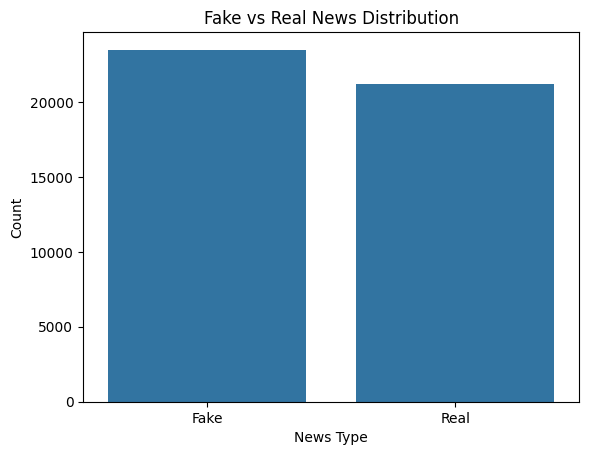

In [32]:
print(df['label'].value_counts())

sns.countplot(x='label', data=df)
plt.title("Fake vs Real News Distribution")
plt.xlabel("News Type")
plt.ylabel("Count")
plt.show()

label
Fake    2547.555882
Real    2378.042337
Name: text_length, dtype: float64


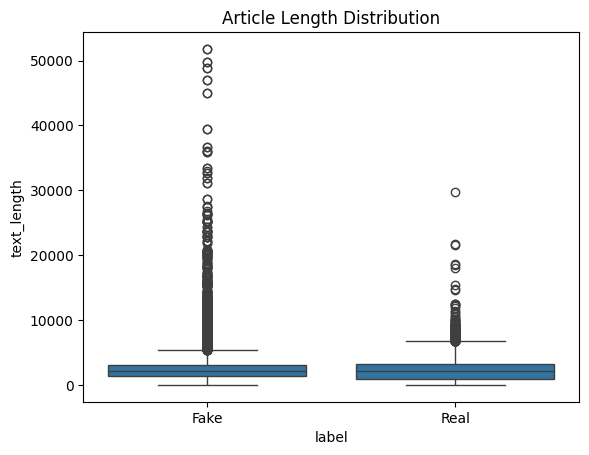

In [33]:
df['text_length'] = df['text'].astype(str).apply(len)

print(df.groupby('label')['text_length'].mean())

sns.boxplot(x='label', y='text_length', data=df)
plt.title("Article Length Distribution")
plt.show()

In [34]:
all_words = ' '.join(df['text'].astype(str)).split()

vocabulary = set(all_words)

print("Total words:", len(all_words))
print("Vocabulary size:", len(vocabulary))

Total words: 18097548
Vocabulary size: 397481


In [35]:
from collections import Counter

words = ' '.join(df['text'].astype(str)).lower().split()

word_count = Counter(words)

print("Top 20 most frequent words:")
print(word_count.most_common(20))

Top 20 most frequent words:
[('the', 997485), ('to', 529999), ('of', 437395), ('a', 403819), ('and', 400976), ('in', 340126), ('that', 228839), ('on', 186204), ('s', 172201), ('for', 169269), ('is', 161776), ('he', 128784), ('with', 115468), ('was', 114083), ('it', 111717), ('as', 101696), ('trump', 101561), ('his', 95321), ('by', 94075), ('said', 92387)]


In [36]:
nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [37]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

df['clean_text'] = df['text'].apply(clean_text)

print(df[['text', 'clean_text']].head())

                                                text  \
0  21st Century Wire says Ben Stein, reputable pr...   
1  WASHINGTON (Reuters) - U.S. President Donald T...   
2  (Reuters) - Puerto Rico Governor Ricardo Rosse...   
3  On Monday, Donald Trump once again embarrassed...   
4  GLASGOW, Scotland (Reuters) - Most U.S. presid...   

                                          clean_text  
0  st century wire says ben stein reputable profe...  
1  washington reuters u president donald trump re...  
2  reuters puerto rico governor ricardo rossello ...  
3  monday donald trump embarrassed country accide...  
4  glasgow scotland reuters u presidential candid...  


In [38]:
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df['clean_text'])

y = df['label']

print("TF-IDF shape:", X.shape)

TF-IDF shape: (44689, 5000)


In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (35751, 5000)
Testing data: (8938, 5000)


In [40]:
print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 35751
Testing samples: 8938

Training class distribution:
label
Fake    18782
Real    16969
Name: count, dtype: int64

Testing class distribution:
label
Fake    4696
Real    4242
Name: count, dtype: int64


In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, roc_auc_score

In [42]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))

Logistic Regression Accuracy: 0.9881405236070709


In [43]:
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

print("Naive Bayes Accuracy:",
      accuracy_score(y_test, nb_pred))

Naive Bayes Accuracy: 0.9336540613112553


In [23]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.9980980085030208


In [24]:
models = {
    "Logistic Regression": lr_pred,
    "Naive Bayes": nb_pred,
    "Random Forest": rf_pred
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label="Fake"),
        "Recall": recall_score(y_test, pred, pos_label="Fake"),
        "F1 Score": f1_score(y_test, pred, pos_label="Fake")
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.988141   0.990594  0.986797  0.988692
1          Naive Bayes  0.933654   0.931986  0.942504  0.937215
2        Random Forest  0.998098   0.998296  0.998083  0.998190


In [25]:
lr_prob = lr_model.predict_proba(X_test)[:, 0]
nb_prob = nb_model.predict_proba(X_test)[:, 0]
rf_prob = rf_model.predict_proba(X_test)[:, 0]

print("Logistic Regression ROC-AUC:",
      roc_auc_score(y_test == "Fake", lr_prob))

print("Naive Bayes ROC-AUC:",
      roc_auc_score(y_test == "Fake", nb_prob))

print("Random Forest ROC-AUC:",
      roc_auc_score(y_test == "Fake", rf_prob))

Logistic Regression ROC-AUC: 0.999113121643145
Naive Bayes ROC-AUC: 0.9796623888477921
Random Forest ROC-AUC: 0.9997550002931662


In [44]:
indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

error_data = df.iloc[test_idx].copy()

error_data['predicted'] = rf_pred

wrong = error_data[error_data['label'] != error_data['predicted']]

print("Total misclassified articles:", len(wrong))

wrong[['title', 'label', 'predicted', 'text']].head(15)

Total misclassified articles: 17


,title,label,predicted,text
183,JAMES COMEY’S Bombshell Pre-Testimony Statement,Fake,Real,Read former FBI Director James Comey s full st...
22891,Graphic: Supreme Court roundup,Real,Fake,
39381,Obama drinks coconut water to cool down in Laos,Real,Fake,U.S. President Barack Obama visited a street m...
7433,Son-in-law Kushner poised to wield clout in Tr...,Real,Fake,WASHINGTON (Reuters) - After winning a primary...
24310,Mosley would have kept Ecclestone at F1 helm,Real,Fake,LONDON (Reuters) - Formula One’s new owners Li...
5135,The American Energy Success Story Obama Won’t ...,Fake,Real,Obama has waisted billions on green energy but...
36782,“GREXIT”? GREEKS VOTE NO ON MORE AUSTERITY IN ...,Fake,Real,"A number of European politicians, including J..."
25297,BREAKING: Man Rushes To Paris Police Station D...,Fake,Real,It doesn t appear the man rushing to doors of ...
2247,The American Energy Success Story Obama Won’t ...,Fake,Real,Obama has waisted billions on green energy but...
35742,BREAKING: MASSIVE CYBER ATTACK ON ALL FEDERAL ...,Fake,Real,This data breach could affect every federal a...


In [45]:
feature_names = tfidf.get_feature_names_out()

importance = rf_model.feature_importances_

feature_df = pd.DataFrame({
    'Word': feature_names,
    'Importance': importance
})

feature_df = feature_df.sort_values(
    by='Importance', ascending=False
)

print(feature_df.head(20))

            Word  Importance
3823     reuters    0.184356
3927        said    0.047922
4788         via    0.034452
1698    featured    0.022030
2196       image    0.020960
4863  washington    0.015633
848          com    0.010726
4551    thursday    0.009934
4887   wednesday    0.009733
4866       watch    0.009276
2847    minister    0.009224
2617        like    0.008839
1914       getty    0.008360
4234   spokesman    0.008255
3620        read    0.007803
3298         pic    0.007789
1563        even    0.007738
4666     tuesday    0.007560
2155       https    0.007190
2197      images    0.006821


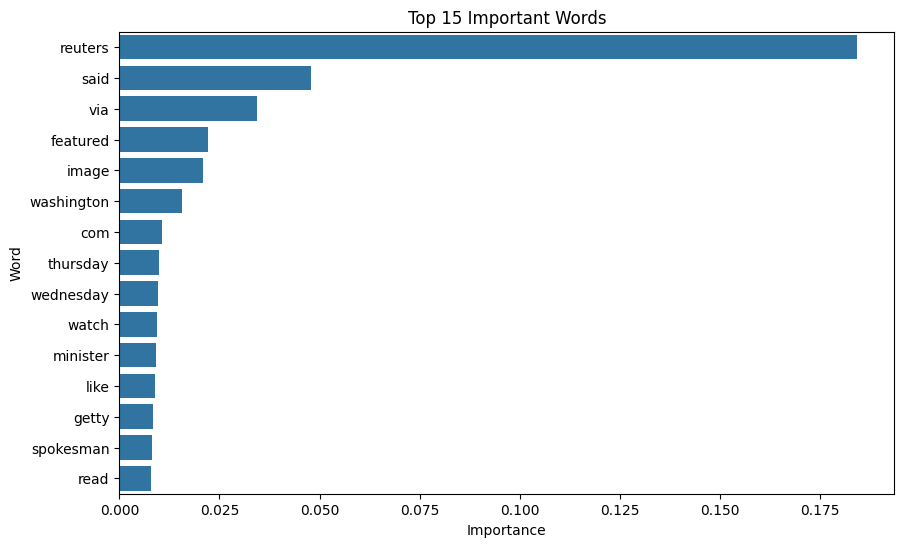

In [46]:
top_words = feature_df.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Word',
    data=top_words
)

plt.title("Top 15 Important Words")
plt.show()

In [47]:
import pickle

with open('model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

with open('vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

print("Model and vectorizer saved successfully")

Model and vectorizer saved successfully


In [48]:
%%writefile app.py

import streamlit as st
import pickle
import re
import pandas as pd

# Load model and vectorizer
model = pickle.load(open('model.pkl', 'rb'))
tfidf = pickle.load(open('vectorizer.pkl', 'rb'))

st.set_page_config(page_title="Fake News Detection", page_icon="📰")

st.sidebar.title("Fake News Detection")

page = st.sidebar.radio(
    "Navigation",
    ["Home", "Predict", "Explain", "About"]
)

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    return text

if page == "Home":

    st.title("Fake vs Real News Detection")

    st.write("""
    This project uses Machine Learning and Natural Language Processing
    to identify whether a news article is Fake or Real.

    The system analyses the text and predicts the category.
    """)

    st.subheader("Project Objectives")

    st.write("- Detect fake and real news")
    st.write("- Use NLP for text preprocessing")
    st.write("- Compare machine learning models")

elif page == "Predict":

    st.title("News Prediction")

    article = st.text_area("Enter your news article")

    if st.button("Predict"):

        if article.strip():

            cleaned = clean_text(article)
            vector = tfidf.transform([cleaned])

            prediction = model.predict(vector)[0]
            probabilities = model.predict_proba(vector)[0]

            classes = list(model.classes_)
            probs = dict(zip(classes, probabilities))

            st.subheader("Prediction")

            st.write("Result:", prediction)

            st.write("Confidence:", round(max(probabilities)*100, 2), "%")

            st.write("Fake Probability:",
                     round(probs.get('Fake', 0)*100, 2), "%")

            st.write("Real Probability:",
                     round(probs.get('Real', 0)*100, 2), "%")

        else:
            st.warning("Please enter an article")

elif page == "Explain":

    st.title("Explain Prediction")

    article = st.text_area("Enter an article to analyse")

    if st.button("Explain"):

        cleaned = clean_text(article)
        vector = tfidf.transform([cleaned])

        prediction = model.predict(vector)[0]

        st.write("Predicted Category:", prediction)

        words = cleaned.split()

        st.write("Important words found in the article:")

        st.write(", ".join(words[:15]))

        st.caption(
            "These are words from the article. "
            "They are not individual causal explanations of the prediction."
        )

elif page == "About":

    st.title("About the Project")

    st.write("""
    Project: Fake vs Real News Detection

    Dataset: Fake and Real News Dataset

    Techniques used:
    - Text preprocessing
    - TF-IDF Vectorization
    - Logistic Regression
    - Naive Bayes
    - Random Forest

    Best performing model: Random Forest
    """)

    st.write("This project was developed using Python and Streamlit.")

Writing app.py


In [49]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 19.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 51.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [50]:
from google.colab import output
import subprocess
import time

process = subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port", "8501",
     "--server.address", "0.0.0.0"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.STDOUT
)

time.sleep(5)

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [51]:
!ps aux | grep streamlit

root        8218  1.1  0.5 1194776 79136 ?       Sl   05:51   0:07 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8501 --server.address 0.0.0.0
root       10927  0.0  0.0   7344  3540 ?        S    06:02   0:00 /bin/bash -c ps aux | grep streamlit
root       10929  0.0  0.0   6548  2368 ?        S    06:02   0:00 grep streamlit


In [52]:
!streamlit run app.py --server.headless true --server.port 8501



2026-11-08 06:02:48.046 Port 8501 is not available


In [53]:
import subprocess
import time

process = subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port=8501",
     "--server.address=0.0.0.0",
     "--server.headless=true"],
    stdout=open("streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(8)

print(open("streamlit.log").read())



2026-11-08 06:03:16.823 Port 8501 is not available



In [54]:
!kill -9 8218

In [55]:
import subprocess
import time

process = subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port", "8501",
     "--server.address", "0.0.0.0",
     "--server.headless", "true"],
    stdout=open("streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(8)

print(open("streamlit.log").read())



2026-11-08 06:04:08.359 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.75.89.6:8501




In [56]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [57]:
!cat streamlit.log



2026-11-08 06:04:08.359 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.75.89.6:8501

2026-11-08 06:04:12.743 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c5-1a3vcb9r2a9lc-c.us-east1.prod.r.colab.dev, host=m-s-use1c5-1a3vcb9r2a9lc.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-08 06:04:17.417 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c5-1a3vcb9r2a9lc-c.us-east1.prod.r.colab.dev, host=m-s-use1c5-1a3vcb9r2a9lc.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-08 06:04:22.448 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1c5-1a3vcb9r2a9lc-c.us-east1.prod.r.colab.dev, host=m-s-use1c5-1a3vcb9r2a9lc.us-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-08 06:04:

In [58]:
import requests

response = requests.get("http://127.0.0.1:8501")

print("Status code:", response.status_code)
print(response.text[:500])

Status code: 200
<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or im


In [59]:
!pkill -f streamlit

In [60]:
import subprocess
import time

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--server.headless=true"
    ],
    stdout=open("streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(8)

print(open("streamlit.log").read())



2026-11-08 06:09:38.317 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.75.89.6:8501




In [61]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>